--- Elemento 1: Matriz de Correlación ---


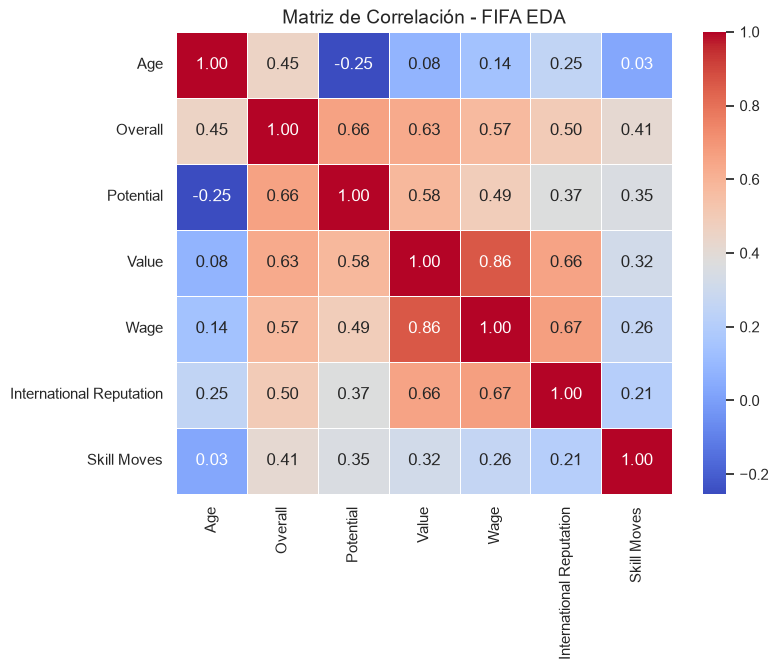

--- Elemento 2: Relación entre la edad y el overall (Scatter Plot) ---


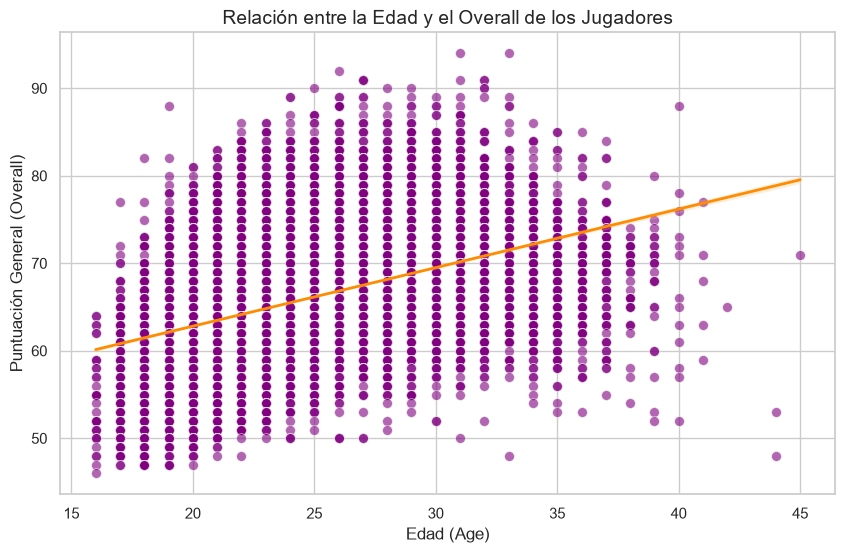

--- Elemento 3: Gráfico de barras de los 15 clubes con más jugadores ---


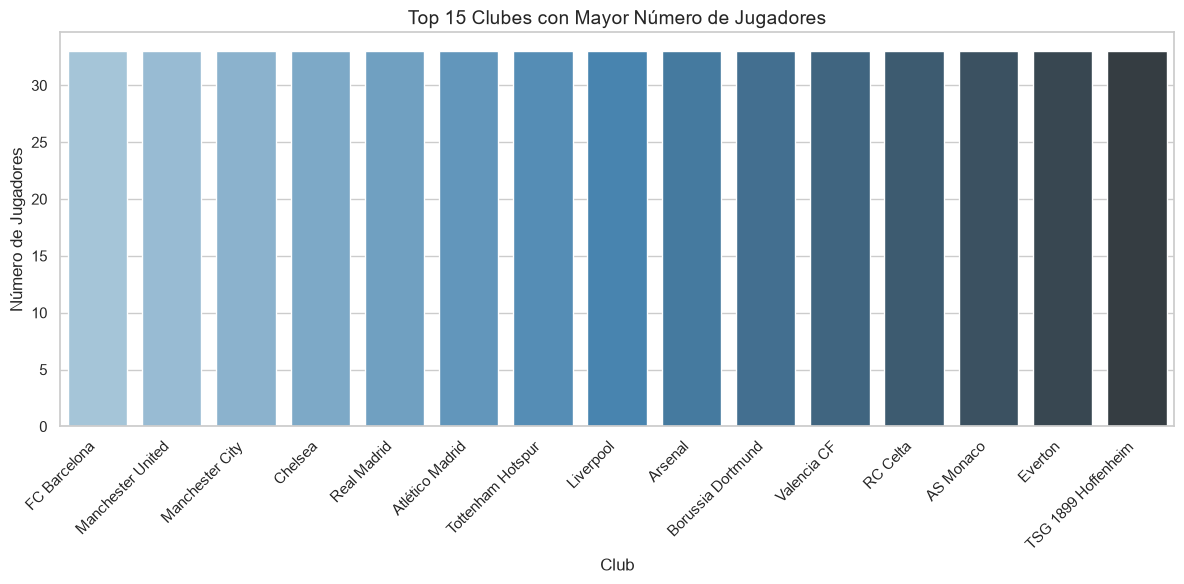

--- Elemento 4: Relación Altura (Height) vs Skill Moves por Pie Hábil (FacetGrid) ---


E:\Archivos de Programa\pitudo\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
E:\Archivos de Programa\pitudo\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)


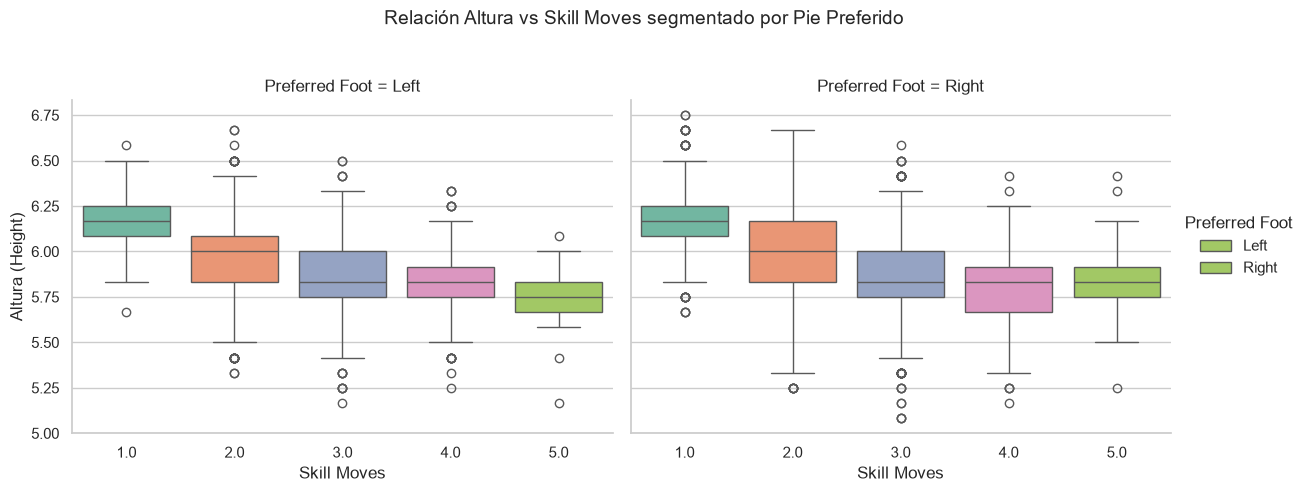

--- Elemento 5: Visualización de Potenciales Cracks ---


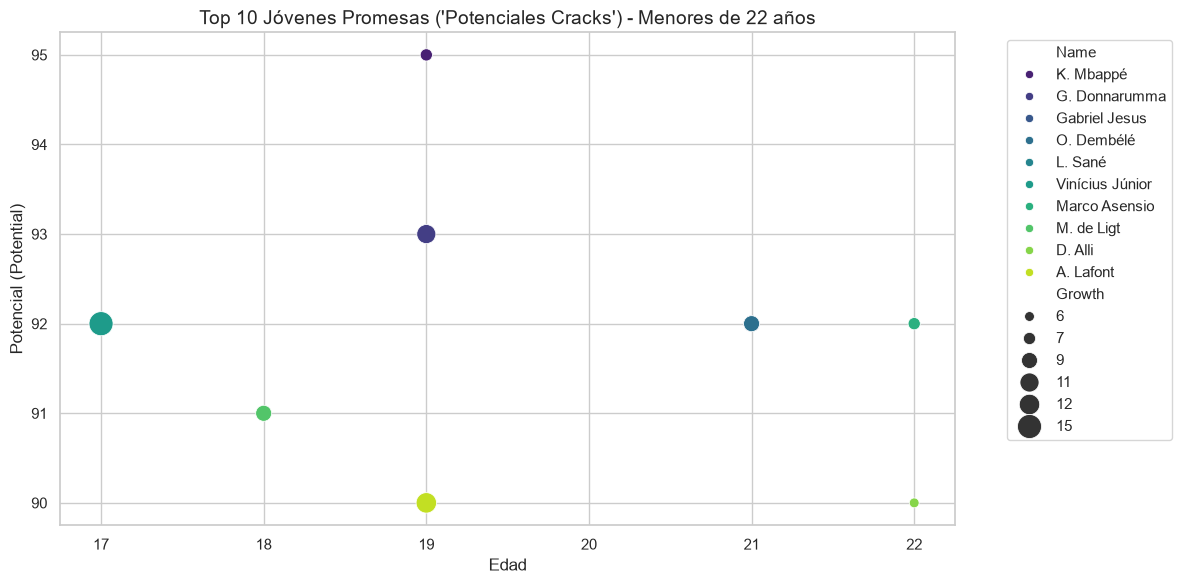

In [2]:
# Importar las bibliotecas necesarias
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Configuración estética para los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# ---------------------------------------------------------
# Cargar el archivo de datos
# ---------------------------------------------------------
df = pd.read_csv("fifa_eda.csv")

# =========================================================
# Elemento 1: Matriz de correlación y mapa de calor (Heatmap)
# =========================================================
print("--- Elemento 1: Matriz de Correlación ---")
# Seleccionamos algunas variables numéricas clave
numeric_cols = [
    "Age",
    "Overall",
    "Potential",
    "Value",
    "Wage",
    "International Reputation",
    "Skill Moves",
]
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5
)
plt.title("Matriz de Correlación - FIFA EDA", fontsize=14)
plt.show()

# =========================================================
# Elemento 2: Gráfico de correlación (Edad vs Overall)
# =========================================================
print(
    "--- Elemento 2: Relación entre la edad y el overall (Scatter Plot) ---"
)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="Age",
    y="Overall",
    alpha=0.6,
    color="purple",
    edgecolor="w",
    s=50,
)
sns.regplot(
    data=df,
    x="Age",
    y="Overall",
    scatter=False,
    color="darkorange",
    line_kws={"linewidth": 2},
)
plt.title("Relación entre la Edad y el Overall de los Jugadores", fontsize=14)
plt.xlabel("Edad (Age)", fontsize=12)
plt.ylabel("Puntuación General (Overall)", fontsize=12)
plt.show()

# Explicación del elemento 2:
# Se observa que la relación no es estrictamente lineal simple: los jugadores jóvenes (18-23)
# muestran una gran dispersión de overall, mientras que el pico de rendimiento óptimo (Overall más alto)
# se concentra típicamente entre los 26 y 32 años. A partir de los 33-35 años, los jugadores con overall
# alto siguen presentes por experiencia, pero disminuyen los promedios generales.

# =========================================================
# Elemento 3: Gráfico de barras por club (Número de jugadores)
# =========================================================
print(
    "--- Elemento 3: Gráfico de barras de los 15 clubes con más jugadores ---"
)
top_clubs = df["Club"].value_counts().head(15)

plt.figure(figsize=(12, 6))
sns.barplot(
    x=top_clubs.index, y=top_clubs.values, palette="Blues_d", hue=top_clubs.index
)
plt.title("Top 15 Clubes con Mayor Número de Jugadores", fontsize=14)
plt.xlabel("Club", fontsize=12)
plt.ylabel("Número de Jugadores", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# =========================================================
# Elemento 4: Gráfico multipanel (Altura vs Skill Moves según pie hábil)
# =========================================================
print(
    "--- Elemento 4: Relación Altura (Height) vs Skill Moves por Pie Hábil (FacetGrid) ---"
)
g = sns.FacetGrid(
    df, col="Preferred Foot", hue="Preferred Foot", height=5, aspect=1.2
)
g.map(
    sns.boxplot,
    "Skill Moves",
    "Height",
    order=sorted(df["Skill Moves"].dropna().unique()),
    palette="Set2",
)
g.add_legend()
g.set_axis_labels("Skill Moves", "Altura (Height)")
g.fig.subplots_adjust(top=0.8)
g.fig.suptitle(
    "Relación Altura vs Skill Moves segmentado por Pie Preferido", fontsize=14
)
plt.show()

# =========================================================
# Elemento 5: Gráfico para mostrar a los potenciales "cracks"
# =========================================================
print("--- Elemento 5: Visualización de Potenciales Cracks ---")
# Definimos "potenciales cracks" como jugadores jóvenes (<= 22 años)
# con un alto potencial (Potential >= 85) y alta diferencia entre potencial y overall
df_young = df[df["Age"] <= 22].copy()
df_young["Growth"] = df_young["Potential"] - df_young["Overall"]
top_cracks = df_young.sort_values(by="Potential", ascending=False).head(10)

plt.figure(figsize=(12, 6))
scatter = sns.scatterplot(
    data=top_cracks,
    x="Age",
    y="Potential",
    size="Growth",
    hue="Name",
    sizes=(50, 300),
    palette="viridis",
)
plt.title(
    "Top 10 Jóvenes Promesas ('Potenciales Cracks') - Menores de 22 años",
    fontsize=14,
)
plt.xlabel("Edad", fontsize=12)
plt.ylabel("Potencial (Potential)", fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()